In [1]:
!pip install yfinance

  Using cached yfinance-1.8.0-py3-none-any.whl.metadata (6.8 kB)
  Using cached peewee-4.5.3-py3-none-any.whl.metadata (10 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached pytz-2026.6-py2.py3-none-any.whl.metadata (22 kB)
  Using cached certifi-2026.10.23-py3-none-any.whl.metadata (2.5 kB)
Using cached yfinance-1.8.0-py3-none-any.whl (158 kB)
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.1 MB ? eta -:--:--
   -------------- ------------------------- 0.8/2.1 MB 2.6 MB/s eta 0:00:01
   ----------------------------- ---------- 1.6/2.1 MB 2.8 MB/s eta 0:00:01
   ---------------------------------------- 2.1/2.1 MB 2.9 MB/s  0:00:00
Using cached certifi-2026.10.23-py3-none-any.whl (135 kB)
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ------- -------------------------------- 0.8/4.0 MB 4.0 MB/s eta 0:00:01
   ------------- -------------------------

[*********************100%***********************]  6 of 6 completed


Dataset shape after cleaning: (1235, 8)

--- Pearson Correlation Matrix (Daily Returns) ---
Ticker    SPY    QQQ   NVDA   MSFT    TLT    GLD
Ticker                                          
SPY     1.000  0.951  0.709  0.687  0.104  0.166
QQQ     0.951  1.000  0.782  0.710  0.085  0.161
NVDA    0.709  0.782  1.000  0.553  0.026  0.094
MSFT    0.687  0.710  0.553  1.000  0.029  0.085
TLT     0.104  0.085  0.026  0.029  1.000  0.212
GLD     0.166  0.161  0.094  0.085  0.212  1.000

SPY vs NVDA Correlation: r = 0.7091, p-value = 2.5122e-189

Training samples: 988 | Testing samples: 247

--- Model A: Simple Linear Regression (CAPM Beta) ---
Estimated Beta (Slope): 2.1621
Alpha (Intercept):      0.001447
Test R2 Score:          0.3598
Test MSE:               0.000381

--- Model B: Multiple Linear Regression (Multi-Factor) ---
  SPY         : -1.6897
  QQQ         : 3.0729
  TLT         : -0.0899
  GLD         : -0.0370
  SPY_Vol_20d : -0.0321
  SPY_Mom_10d : -0.0017
Test R2 Score:          

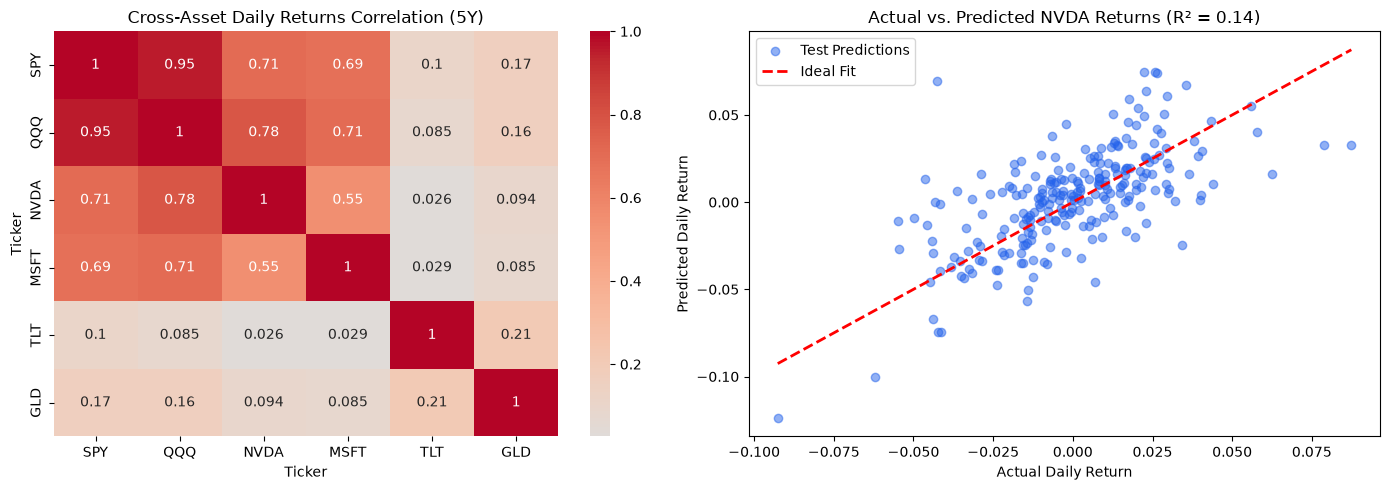

In [9]:

import numpy as np
import pandas as pd
import yfinance as yf
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

# ==========================================
# 1. DATA ACQUISITION & WRANGLING
# ==========================================
tickers = ['SPY', 'QQQ', 'NVDA', 'MSFT', 'TLT', 'GLD']
print(f"Downloading 5 years of historical data for: {tickers}...")

raw_data = yf.download(tickers, period="5y", auto_adjust=True)['Close']

# Calculate daily percentage returns and drop missing values
returns = raw_data.pct_change().dropna()

# Feature Engineering: Add rolling volatility and momentum for SPY
df = returns.copy()
df['SPY_Vol_20d'] = df['SPY'].rolling(window=20).std()
df['SPY_Mom_10d'] = raw_data['SPY'].pct_change(periods=10)
df = df.dropna()

print(f"Dataset shape after cleaning: {df.shape}")

# ==========================================
# 2. CORRELATION & STATISTICAL SIGNIFICANCE
# ==========================================
corr_matrix = df[tickers].corr()
print("\n--- Pearson Correlation Matrix (Daily Returns) ---")
print(corr_matrix.round(3))

# Test statistical significance between Market (SPY) and Tech Stock (NVDA)
pearson_coef, p_value = stats.pearsonr(df['SPY'], df['NVDA'])
print(f"\nSPY vs NVDA Correlation: r = {pearson_coef:.4f}, p-value = {p_value:.4e}")

# ==========================================
# 3. TRAIN / TEST SPLIT (TIME-SERIES SAFE)
# ==========================================
features = ['SPY', 'QQQ', 'TLT', 'GLD', 'SPY_Vol_20d', 'SPY_Mom_10d']
target = 'NVDA'

X = df[features]
y = df[target]

# Chronological split (80% train, 20% test) to prevent look-ahead bias
split_idx = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"\nTraining samples: {len(X_train)} | Testing samples: {len(X_test)}")

# ==========================================
# 4. REGRESSION MODELING & EVALUATION
# ==========================================

# Model A: Simple Linear Regression (CAPM Beta estimation vs SPY)
slr = LinearRegression()
slr.fit(X_train[['SPY']], y_train)
y_pred_slr = slr.predict(X_test[['SPY']])

print("\n--- Model A: Simple Linear Regression (CAPM Beta) ---")
print(f"Estimated Beta (Slope): {slr.coef_[0]:.4f}")
print(f"Alpha (Intercept):      {slr.intercept_:.6f}")
print(f"Test R2 Score:          {r2_score(y_test, y_pred_slr):.4f}")
print(f"Test MSE:               {mean_squared_error(y_test, y_pred_slr):.6f}")

# Model B: Multiple Linear Regression (Multi-Factor Model)
mlr = LinearRegression()
mlr.fit(X_train, y_train)
y_pred_mlr = mlr.predict(X_test)

print("\n--- Model B: Multiple Linear Regression (Multi-Factor) ---")
for feat, coef in zip(features, mlr.coef_):
    print(f"  {feat:<12}: {coef:.4f}")
print(f"Test R2 Score:          {r2_score(y_test, y_pred_mlr):.4f}")
print(f"Test MSE:               {mean_squared_error(y_test, y_pred_mlr):.6f}")

# Model C: Ridge Regression with Standardization & Polynomial Features (Degree 2)
poly_ridge = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('ridge', Ridge(alpha=1.0))
])
poly_ridge.fit(X_train, y_train)
y_pred_poly = poly_ridge.predict(X_test)

print("\n--- Model C: Polynomial Ridge Regression (Degree 2) ---")
print(f"Test R2 Score:          {r2_score(y_test, y_pred_poly):.4f}")
print(f"Test MSE:               {mean_squared_error(y_test, y_pred_poly):.6f}")

# ==========================================
# 5. VISUALIZATION FOR GITHUB PORTFOLIO
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Correlation Heatmap
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, ax=axes[0])
axes[0].set_title('Cross-Asset Daily Returns Correlation (5Y)')

# Plot 2: Actual vs Predicted Returns (Multiple Regression on Test Set)
axes[1].scatter(y_test, y_pred_mlr, alpha=0.5, color='#2563eb', label='Test Predictions')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit')
axes[1].set_title(f'Actual vs. Predicted NVDA Returns (R² = {r2_score(y_test, y_pred_mlr):.2f})')
axes[1].set_xlabel('Actual Daily Return')
axes[1].set_ylabel('Predicted Daily Return')
axes[1].legend()

plt.tight_layout()
plt.savefig('regression_results.png', dpi=300)
plt.show()

In [8]:
!pip install scikit-learn

  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.2 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.2 MB 1.3 MB/s eta 0:00:07
   --- ------------------------------------ 0.8/8.2 MB 1.3 MB/s eta 0:00:06
   ----- ---------------------------------- 1.0/8.2 MB 1.5 MB/s eta 0:00:05
   ------- -------------------------------- 1.6/8.2 MB 1.6 MB/s eta 0:00:05
   -------- ------------------------------- 1.8/8.2 MB 1.6 MB/s eta 0:00:04
   ----------- ---------------------------- 2.4/8.2 MB 1.7 MB/s eta 0:00:04
   -------------- ------------------------- 2.9/8.2 MB 1.8 MB/s eta 0:00

In [ ]:
!pip install matplotlib